**pipeline**

generate distribution
- vary size
- vary length
- vary sparsity: i.e. how many 1s does a vector have (implies similarity of reference representations to each other: all reports are the same vs all reports are unique and everything in between )

compute measure
- pr_i
- similarity
- rarity

plot
- sparsity vs each measure for all vectors
- size in relation to each measure
- length in relation to each measure

In [25]:
import numpy as np
import math
import numpy as np

Helpers

In [52]:
def find_max_sparsity(distributions_with_pooled_populations):
  max_sparsity = 0
  print("find_max_sparsity length:")
  print(str(len(distributions_with_pooled_populations[0][1])))
  for ref_reps, pooled_population in distributions_with_pooled_populations:
    for ref_rep in ref_reps:
      sparsity = sum(ref_rep)/ len(pooled_pop)
      if(sparsity > max_sparsity):
        max_sparsity = sparsity
  return max_sparsity

**GENERATE DISTRIBUTIONS**

In [54]:
def generate_mixed_sparsity_distribution(length=10, num_ref_reps=10):
    distributions_with_pooled_populations = []
    # 1. Determine the length of each binary representation (number of bits needed)
    # To represent the number 'length' in binary, we check how many bits are required.
    max_range = 2**length

    for j in range(0,3):
      # 2. Build the full pool of unique binary vectors up to 'length'
      full_ref_reps = []
      for i in range(max_range):
          # Convert number to simple binary string, pad with zeros, and convert to integer list
          bin_str = bin(i)[2:].zfill(length)
          vector = [int(bit) for bit in bin_str]
          full_ref_reps.append(vector)

      # Print the size of the generated unique vector pool
      print(f"Length of full_ref_reps: {len(full_ref_reps)}")

      # 3. Randomly choose indices from our pool to build the ref_reps
      # (Using a default of 10 vectors if not specified)
      chosen_indices = np.random.randint(0, len(full_ref_reps), size=num_ref_reps)
      ref_reps = np.array([full_ref_reps[idx] for idx in chosen_indices])

      # 4. Compute pooled population
      pooled_population = ref_reps.sum(axis=0)

      distributions_with_pooled_populations.append((ref_reps, pooled_population))

    return distributions_with_pooled_populations

In [27]:
def generate_distributions(print=False, num_vectors=10, length=100, max_sparsity=0.4):
  distributions_with_pooled_populations = []
  all_sparsities = [0.01, 0.1, 0.3, 0.6, 0.9]
  sparsities = [s for s in all_sparsities if s <= max_sparsity]

  for sparsity in sparsities:
    ref_reps = generate_distribution(sparsity=sparsity, length=length, num_vectors=num_vectors)
    pooled_population = ref_reps.sum(axis=0)
    if print:
      print("Sparsity:" + str(sparsity))
      print_ref_reps_statistics(ref_reps)
      print_pooled_population_statistics(pooled_population)

    distributions_with_pooled_populations.append((ref_reps, pooled_population))



  return distributions_with_pooled_populations


In [28]:
#num_vectors := number of reference representations
#length := total number of distinct reported features
#number of 1s in each vector := specific features reported by individual i in reference representation i
def generate_distribution(num_vectors=100, length=1000, sparsity=0.02):
    #create reference representations
    vectors = []
    for _ in range(num_vectors):
        while True:
            vec = np.random.choice([0, 1], size=length, p=[1 - sparsity, sparsity])
            sum_val = np.sum(vec)
            if 0 < sum_val < length:
                vectors.append(vec)
                break
    vectors = np.array(vectors)

    # guarantee that each position (column) has at least one '1'
    pooled = vectors.sum(axis=0)
    zero_cols = np.where(pooled == 0)[0]

    # for any column containing all zeros, pick a random vector to set that index to 1
    for col in zero_cols:
        random_vec_idx = np.random.randint(num_vectors)
        vectors[random_vec_idx, col] = 1

    return vectors

  #create_pooled_population

In [29]:
def print_ref_reps_statistics(vectors):
  print("--- Reference Representation Statistics ---")
  print(f"Shape of the generated array: {vectors.shape}")
  print(f"Minimum sum of a vector: {vectors.sum(axis=1).min()} (Should be > 0)")
  print(f"Maximum sum of a vector: {vectors.sum(axis=1).max()} (Should be < 1000)")
  print(f"Average density of 1s: {vectors.mean():.4f}")

  # Display a sample of the first vector
  print(f"\nSample of the first vector (first 50 elements):\n{vectors[0][:50]}")

In [30]:
def print_pooled_population_statistics(pooled_population):
  print("--- Pooled Population Statistics ---")
  print(f"Shape of pooled_population: {pooled_population.shape}")
  print(f"Minimum value: {pooled_population.min()}")
  print(f"Maximum value: {pooled_population.max()}")
  print(f"Mean value: {pooled_population.mean():.4f}")
  print("\n")


In [31]:
def pick_x(vectors, mode="external", length=1000, sparsity=0.02):
  if(mode=="random"):
    x = np.random.choice([0, 1], size=length, p=[1 - sparsity, sparsity])
    return x
  if(mode=="internal"):
    copy_vector = np.random.choice([0, length])
    x = vectors[copy_vector]
    return x

**CALCULATE MEASURES**

1. Collision Probability Pr_i
2. Similiarity
3. Rarity

In [32]:
#1. collision probabilities
def compute_pr_i(a, b):
    """
    Computes the multivariate probability for arbitrary length vectors.

    Parameters:
    a (array-like): The pooled population vector (sum of all vectors)
    b (array-like): An individual vector from vectors
    """
    a = np.array(a, dtype=int)
    b = np.array(b, dtype=int)

    if len(a) != len(b):
        raise ValueError("Vectors 'a' and 'b' must have the same length.")

    sum_a = int(np.sum(a))
    sum_b = int(np.sum(b))

    # Calculate numerator
    numerator = 1
    for ai in a:
        numerator *= math.factorial(ai)
    numerator *= math.factorial(sum_b)
    numerator *= math.factorial(sum_a - sum_b)

    # Calculate denominator
    denominator = 1
    for bi in b:
        denominator *= math.factorial(bi)
    for ai, bi in zip(a, b):
        denominator *= math.factorial(ai - bi)
    denominator *= math.factorial(sum_a)

    return numerator / denominator

In [45]:
import math
import numpy as np

def compute_log_factorial_sum(vector, pooled_pop=None, mode="denominator"):
    """
    Computes the sum of log-factorials to avoid overflow/underflow.
    """
    if mode == "numerator":
        # numerator log-factorials
        sum_a = int(np.sum(pooled_pop))
        sum_b = int(np.sum(vector))
        log_sum = 0.0
        for ai in pooled_pop:
            log_sum += math.log(math.factorial(int(ai)))
        log_sum += math.log(math.factorial(sum_b))
        log_sum += math.log(math.factorial(sum_a - sum_b))
        return log_sum
    else:
        # denominator log-factorials
        sum_a = int(np.sum(pooled_pop))
        log_sum = 0.0
        for bi in vector:
            log_sum += math.log(math.factorial(int(bi)))
        for ai, bi in zip(pooled_pop, vector):
            log_sum += math.log(math.factorial(int(ai - bi)))
        log_sum += math.log(math.factorial(sum_a))
        return log_sum

def compute_normalized_pr_i(a, b):
    """
    Computes the collision probability Pr_i normalized by the theoretical maximum
    probability, using log-space arithmetic to prevent numerical underflow.
    """
    a = np.array(a, dtype=int)
    b = np.array(b, dtype=int)
    sum_b = int(np.sum(b))

    # 1. Create the optimal theoretical vector of same size
    sorted_indices = np.argsort(a)[::-1]
    optimal_b = np.zeros_like(b)
    optimal_b[sorted_indices[:sum_b]] = 1

    # 2. Calculate log-probabilities to avoid underflow
    log_num_raw = compute_log_factorial_sum(b, pooled_pop=a, mode="numerator")
    log_den_raw = compute_log_factorial_sum(b, pooled_pop=a, mode="denominator")
    log_raw_pr = log_num_raw - log_den_raw

    log_num_max = compute_log_factorial_sum(optimal_b, pooled_pop=a, mode="numerator")
    log_den_max = compute_log_factorial_sum(optimal_b, pooled_pop=a, mode="denominator")
    log_max_pr = log_num_max - log_den_max

    # 3. Compute ratio in log-space: log(raw / max) = log(raw) - log(max)
    log_normalized = log_raw_pr - log_max_pr

    try:
        return math.exp(log_normalized)
    except OverflowError:
        return 1.0

In [34]:
# Quick demonstration of the difference between original and normalized Pr_i
if 'distributions_with_pooled_populations' in globals():
    ref_reps, pooled_pop = distributions_with_pooled_populations[0] # Grab the first sparsity run
    sample_vector = ref_reps[0]

    raw_val = compute_pr_i(pooled_pop, sample_vector)
    norm_val = compute_normalized_pr_i(pooled_pop, sample_vector)

    print(f"Vector Active Features (Sparsity count): {np.sum(sample_vector)}")
    print(f"Raw Collision Probability (Pr_i): {raw_val:.4e}")
    print(f"Normalized Collision Probability: {norm_val:.6f} (Proximity to theoretical limit)")
else:
    print("Run the MAIN cell first to test this demonstration on live data.")

Vector Active Features (Sparsity count): 9
Raw Collision Probability (Pr_i): 8.4282e-22
Normalized Collision Probability: 0.000073 (Proximity to theoretical limit)


In [35]:
from sklearn.metrics import jaccard_score

def compute_similarity(x, reference_representation):
  return jaccard_score(x, reference_representation)


**Plot Measures**

Collision Probability
  - plot distribution of pr_i in relation to sparsity

In [36]:
import matplotlib.pyplot as plt
import numpy as np

def plot_pri_boxplots():
    # 1. Convert to numpy array and handle zero probabilities safely
    pr_is_arr = np.array(pr_is)
    underflow_floor = 1e-320
    clipped_pr_is = np.where(pr_is_arr == 0.0, underflow_floor, pr_is_arr)
    log_probabilities = np.log10(clipped_pr_is)

    # 2. Extract single sparsities that match our generated groups
    # Since max_sparsity is 0.3, we have 0.01, 0.1, and 0.3 (100 vectors each)
    single_sparsities = [0.01, 0.1, 0.3]

    # Group the computed probabilities sequentially per sparsity level
    grouped_data = []
    labels = []
    for idx, s in enumerate(single_sparsities):
        start_idx = idx * 100
        end_idx = start_idx + 100
        segment = log_probabilities[start_idx:end_idx]
        if len(segment) > 0:
            grouped_data.append(segment)
            labels.append(str(s))

    # 3. Create Boxplot
    plt.figure(figsize=(10, 6))
    plt.boxplot(grouped_data, tick_labels=labels, patch_artist=True,
                boxprops=dict(facecolor='lightcoral', color='darkred'),
                medianprops=dict(color='black', linewidth=1.5))

    # 4. Overlay individual data points (with jitter)
    for idx, segment in enumerate(grouped_data):
        x = np.random.normal(idx + 1, 0.04, size=len(segment))
        plt.scatter(x, segment, alpha=0.4, color='darkred', edgecolor='none', s=25)

    plt.xlabel('Sparsity Level', fontsize=12)
    plt.ylabel('Log10(Collision Probability $Pr_i$)', fontsize=12)
    plt.title('Distribution of Collision Probabilities ($Pr_i$) vs. Sparsity', fontsize=14)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig('collision_probability_boxplot.png', dpi=300)
    plt.show()

In [37]:
import matplotlib.pyplot as plt
import numpy as np

def plot_rarity_boxplots():
    # 1. Get the sorted active sparsity levels that we actually have data for
    active_sparsities = sorted(list(rarities.keys()))

    # 2. Group the computed rarity values per sparsity level
    grouped_data = []
    labels = []
    for s in active_sparsities:
        segment = rarities[s]
        if len(segment) > 0:
            grouped_data.append(segment)
            labels.append(str(s))

    # 3. Create Boxplot
    plt.figure(figsize=(10, 6))
    plt.boxplot(grouped_data, tick_labels=labels, patch_artist=True,
                boxprops=dict(facecolor='lightgreen', color='darkgreen'),
                medianprops=dict(color='black', linewidth=1.5))

    # 4. Overlay individual data points (with jitter)
    for idx, segment in enumerate(grouped_data):
        x = np.random.normal(idx + 1, 0.04, size=len(segment))
        plt.scatter(x, segment, alpha=0.4, color='darkgreen', edgecolor='none', s=25)

    plt.xlabel('Sparsity Level', fontsize=12)
    plt.ylabel('Median Feature Rarity (%)', fontsize=12)
    plt.title('Distribution of Rarity (Median Feature Rarity) vs. Sparsity', fontsize=14)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig('rarity_boxplot.png', dpi=300)
    plt.show()

In [38]:
def plot(measure="pri"):
  if measure == "pri":
    plot_pri_boxplots()
  elif measure == "similarity":
    # Original similarity boxplot
    plt.figure(figsize=(10, 6))
    data_to_plot = []
    labels = []
    for s in sorted(similarities.keys()):
        data_to_plot.append(similarities[s])
        labels.append(str(s))

    plt.boxplot(data_to_plot, tick_labels=labels, patch_artist=True,
                boxprops=dict(facecolor='lightblue', color='blue'),
                medianprops=dict(color='red', linewidth=1.5))

    for idx, s in enumerate(sorted(similarities.keys())):
        y = similarities[s]
        x = np.random.normal(idx + 1, 0.04, size=len(y))
        plt.scatter(x, y, alpha=0.4, color='darkblue', edgecolor='none', s=25)

    plt.xlabel('Sparsity Level', fontsize=12)
    plt.ylabel('Jaccard Similarity with Random Vector x', fontsize=12)
    plt.title('Distribution of Jaccard Similarities vs. Sparsity', fontsize=14)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig('similarity_vs_sparsity.png', dpi=300)
    plt.show()
  elif measure == "rarity":
    #plot_rarity_histograms()
    plot_rarity_boxplots()

In [39]:
import matplotlib.pyplot as plt
import numpy as np

def plot_pri_histograms():
    # Convert and secure log probabilities
    pr_is_arr = np.array(pr_is)
    underflow_floor = 1e-320
    clipped_pr_is = np.where(pr_is_arr == 0.0, underflow_floor, pr_is_arr)
    log_probabilities = np.log10(clipped_pr_is)

    # Explicit boundaries mapping the vectors
    # Each of the 5 sparsities has 100 main vectors and 20 mixed vectors
    single_sparsities = [0.01, 0.1, 0.3, 0.6, 0.9]

    # Let's map slices of log_probabilities to each sparsity level
    # Since they were generated sequentially in generate_distributions
    # each sparsity chunk has 100 vectors.
    fig, axes = plt.subplots(len(single_sparsities), 1, figsize=(10, 15), sharex=True)

    # Calculate overall limits to keep consistent scale across subplots
    x_min, x_max = np.min(log_probabilities), np.max(log_probabilities)
    padding = (x_max - x_min) * 0.05 if x_max != x_min else 1.0

    for idx, s in enumerate(single_sparsities):
        start_idx = idx * 100
        end_idx = start_idx + 100
        segment_y = log_probabilities[start_idx:end_idx]

        ax = axes[idx]
        ax.hist(segment_y, bins=15, color='royalblue', edgecolor='black', alpha=0.7)
        ax.set_title(f'Sparsity {s} (N = {len(segment_y)} Vectors)', fontsize=12)
        ax.set_ylabel('Count', fontsize=10)
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.set_xlim(x_min - padding, x_max + padding)

    plt.xlabel('Log10(Collision Probability $Pr_i$)', fontsize=12)
    plt.suptitle('Distribution of Collision Probabilities ($Pr_i$) by Sparsity Level', fontsize=14, y=0.98)
    plt.tight_layout()
    plt.savefig('collision_probability_histograms.png', dpi=300)
    plt.show()

In [40]:
import matplotlib.pyplot as plt
import numpy as np

def plot_rarity_histograms():
    # Get the sparsity levels that we actually have data for
    active_sparsities = sorted(list(rarities.keys()))

    fig, axes = plt.subplots(len(active_sparsities), 1, figsize=(10, 4 * len(active_sparsities)), sharex=False)

    # If there is only one active sparsity, wrap axes in a list
    if len(active_sparsities) == 1:
        axes = [axes]

    for idx, s in enumerate(active_sparsities):
        segment_y = rarities[s]
        ax = axes[idx]

        # Plotting the histogram of rarity values
        ax.hist(segment_y, bins=15, color='mediumseagreen', edgecolor='black', alpha=0.7)
        ax.set_title(f'Sparsity {s} (N = {len(segment_y)} Vectors)', fontsize=12)
        ax.set_xlabel('Median Feature Rarity (%)', fontsize=10)
        ax.set_ylabel('Number of Reference Reps', fontsize=10)
        ax.grid(True, linestyle='--', alpha=0.5)

    plt.suptitle('Distribution of Rarity (Median Feature Rarity) by Sparsity Level', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig('rarity_histograms.png', dpi=300)
    plt.show()

Length of full_ref_reps: 4194304
Length of full_ref_reps: 4194304
Length of full_ref_reps: 4194304
find_max_sparsity length:
22
Loading pr_is from pr_is_backup.npy...
Loaded 300 items.
Computing similarity ...
Computing similarity ...
Computing similarity ...
Similarity computation complete.
Sparsity 0: Calculated 100 similarities.
--- Average Similarity per Sparsity Level ---
Sparsity 0   : Average Jaccard Similarity = 0.048502

--- Average Rarity per Sparsity Level ---
Sparsity 0   : Average Rarity = 49.980000


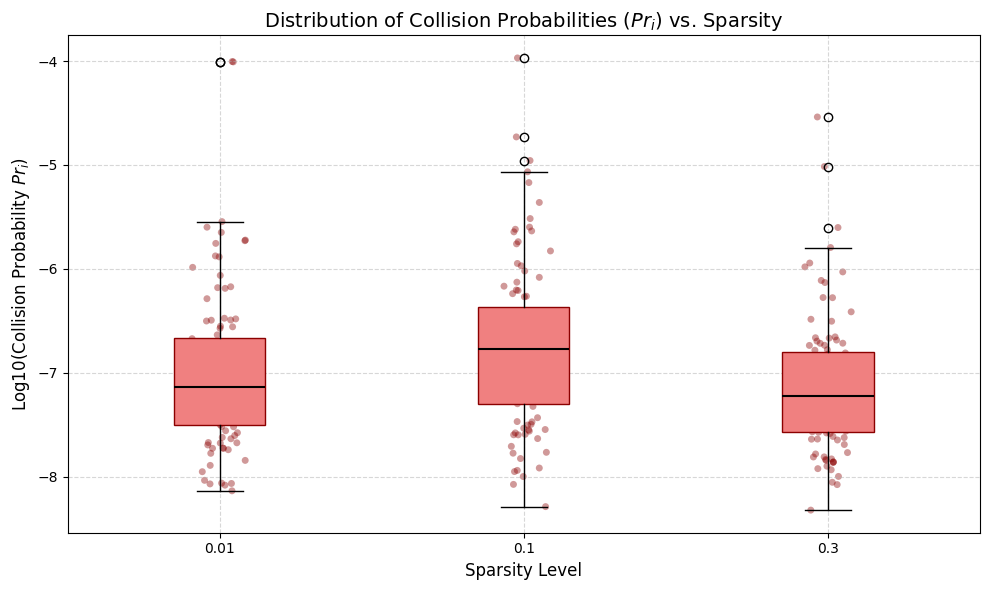

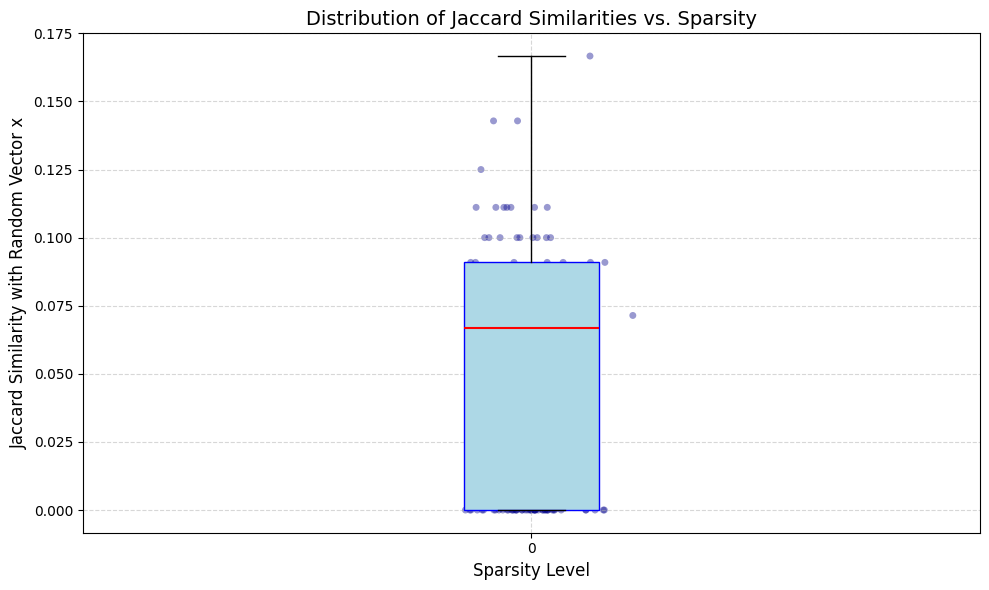

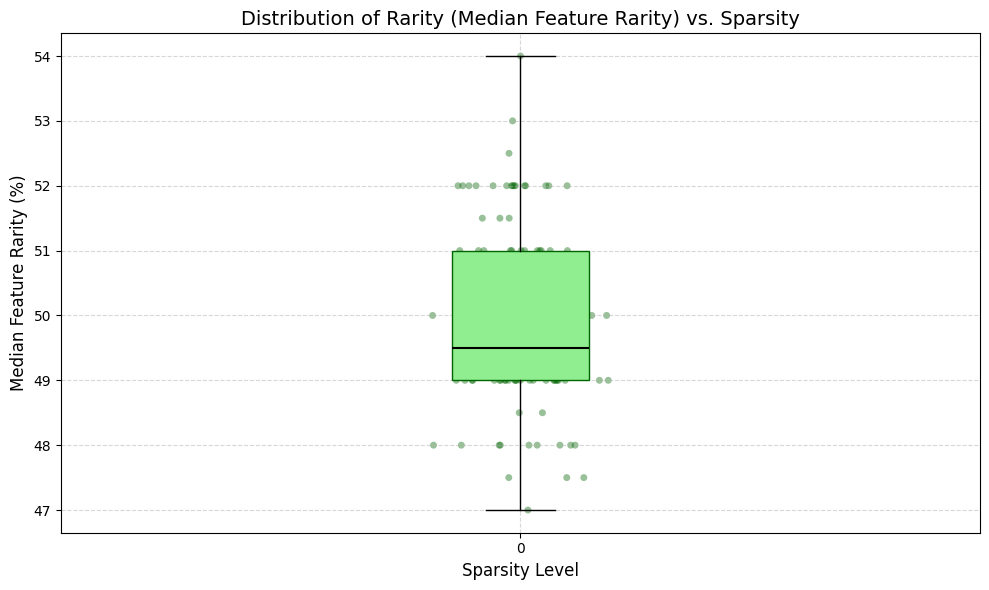

In [57]:
"""
MAIN:
1. generate reference representations and pooled populations of varying sparsity
2. compute measures
    - pr_i
    - similarity
    - rarity
3. plot relations
    - sparsity vs each measure for all vectors
    - similarity vs each  measure for all vectors
    - size in relation to each measure
    - length in relation to each measure
"""
import os
import numpy as np

length=1000
max_sparsity=0.3

# 1. generate reference representations and pooled populations of varying sparsity
#distributions_with_pooled_populations = generate_distributions(num_vectors=100, length=length, max_sparsity=max_sparsity)
distributions_with_pooled_populations = generate_mixed_sparsity_distribution(length=22, num_ref_reps = 100)
max_sparsity = find_max_sparsity(distributions_with_pooled_populations)


# 2. compute measures
# 2.1 Collision Probability Pr_i (with backup check)
backup_file = 'pr_is_backup.npy'
use_backup = (max_sparsity > 0.4) #False # only use backup when computing with max sparsity > 0.4

if (os.path.exists(backup_file) and use_backup):
  print(f"Loading pr_is from {backup_file}...")
  pr_is = np.load(backup_file).tolist()
  print(f"Loaded {len(pr_is)} items.")
else:
  print("Backup not found. Computing pr_is...")
  pr_is = []
  for ref_reps, pooled_pop in distributions_with_pooled_populations:
    for ref_rep in ref_reps:
      pr_i = compute_pr_i(pooled_pop, ref_rep)
      #pr_i = compute_normalized_pr_i(pooled_pop, ref_rep)
      pr_is.append(pr_i)
    print(len(pr_is))

  # Save to backup
  np.save(backup_file, np.array(pr_is))
  print(f"Saved pr_is to {backup_file}")

# 2.2 Similarity
similarities = {}

for (ref_reps, pooled_pop) in distributions_with_pooled_populations:
  i=0
  similarities[i] = []
  print(f"Computing similarity ...")
  x = pick_x(ref_reps, mode="random", length=len(pooled_pop), sparsity=0.02)
  for ref_rep in ref_reps:
    similarity = compute_similarity(x, ref_rep)
    similarities[i].append(similarity)
  i+=1


"""

similarities = {}
all_sparsities = [0.01, 0.1, 0.3, 0.6, 0.9]
sparsities = [s for s in all_sparsities if s <= max_sparsity]


for idx, (ref_reps, pooled_pop) in enumerate(distributions_with_pooled_populations):
  current_sparsity = sparsities[idx]
  similarities[current_sparsity] = []
  #TODO: implement different input representation selection scenarios and interpret the impact on the plotted results
  x = pick_x(ref_reps, mode="random", length=len(pooled_pop), sparsity=0.02)
  for ref_rep in ref_reps:
    similarity = compute_similarity(x, ref_rep)
    similarities[current_sparsity].append(similarity)
"""

print("Similarity computation complete.")
for s, sim_list in similarities.items():
  print(f"Sparsity {s}: Calculated {len(sim_list)} similarities.")
  # Calculate and print the average similarity per sparsity level
  print("--- Average Similarity per Sparsity Level ---")
  for s, sim_list in similarities.items():
      if len(sim_list) > 0:
          avg_sim = np.mean(sim_list)
          print(f"Sparsity {s:<4}: Average Jaccard Similarity = {avg_sim:.6f}")
      else:
          print(f"Sparsity {s:<4}: No similarities calculated.")

# 2.3 Rarity
# Compute rarity based on median feature rarity of active features
rarities = {}
for (ref_reps, pooled_pop) in distributions_with_pooled_populations:
  i=0
  rarities[i] = []

  num_reps = len(ref_reps)

  # Feature rarity of each feature (column) across the reference reps:
  # 100 * (number of ref reps that have this feature active) / (total number of ref reps)
  # Since pooled_pop is the column sum of ref_reps, we can use pooled_pop directly.
  feature_rarity = 100.0 - (100.0 * pooled_pop / num_reps)

  for ref_rep in ref_reps:
    active_features = (ref_rep == 1)
    if np.any(active_features):
      # Rarity of representation is the median of active feature rarities
      vector_rarity = np.median(feature_rarity[active_features])
    else:
      vector_rarity = 0.0
    rarities[i].append(vector_rarity)
  i+=1

print("\n--- Average Rarity per Sparsity Level ---")
for s, rar_list in rarities.items():
  avg_rar = np.mean(rar_list)
  print(f"Sparsity {s:<4}: Average Rarity = {avg_rar:.6f}")

# 3. plot
plot(measure="pri")
plot(measure="similarity")
plot(measure="rarity")

#4. TODO: implement a mixed sparsity population and compute everything for multiple constellations thereof

Extras

In [48]:
# Demonstration of Normalized Pr_i calculation across different sparsity levels
if 'distributions_with_pooled_populations' in globals():
    print("--- Normalizing Pr_i Across Sparsity Groups ---\n")
    for idx, s in enumerate(sparsities):
        ref_reps, pooled_pop = distributions_with_pooled_populations[idx]
        sample_vector = ref_reps[0]

        norm_vals = []
        for ref_rep in ref_reps:
            norm_vals.append(compute_normalized_pr_i(pooled_pop, ref_rep))

        avg_norm_val = np.mean(norm_vals)

        print(f"Sparsity Level: {s}")
        print(f"  - Active Features: {np.sum(sample_vector)}")
        print(f"  - Average Normalized Pr_i (Decimal): {avg_norm_val:.6f}")
        print(f"  - Average Normalized Pr_i (Scientific): {avg_norm_val:.4e}")
        print("-" * 45)
else:
    print("Please run your main simulation cell first to instantiate the data.")

--- Normalizing Pr_i Across Sparsity Groups ---

Sparsity Level: 0.01
  - Active Features: 17
  - Average Normalized Pr_i (Decimal): 0.000098
  - Average Normalized Pr_i (Scientific): 9.7630e-05
---------------------------------------------
Sparsity Level: 0.1
  - Active Features: 95
  - Average Normalized Pr_i (Decimal): 0.000000
  - Average Normalized Pr_i (Scientific): 1.0147e-14
---------------------------------------------
Sparsity Level: 0.3
  - Active Features: 322
  - Average Normalized Pr_i (Decimal): 0.000000
  - Average Normalized Pr_i (Scientific): 2.8026e-18
---------------------------------------------
